# TP 2 : Segmentation non supervisée des régimes de fonctionnement par K-means

**Ressource :** R3.13 - Maintenance Prédictive & Data Science  
**Séance 2 :** Segmentation non supervisée  
**Auteur :** Étudiant en informatique / Data Science  
**Graine aléatoire :** seed = 42

---

## Objectifs du TP

Dans ce deuxième TP, on cherche à identifier de manière non supervisée les différents régimes de marche des 6 machines de l'atelier à partir de leurs capteurs physiques.

Le travail se décompose en cinq étapes :
1. Implémenter l'algorithme K-means avec NumPy (affectation, mise à jour des centroïdes, inertie) et vérifier la concordance avec l'implémentation de scikit-learn.
2. Déterminer le nombre de groupes k adapté en croisant la méthode du coude et l'indice de silhouette moyen.
3. Segmenter les données en k = 4 régimes ordonnés par température croissante, et dresser leur profil physique moyen.
4. Proposer une dénomination claire pour chaque régime et formuler des préconisations pour la maintenance.
5. Mesurer concrètement l'effet de l'échelle des grandeurs physiques en comparant la segmentation sur données standardisées et sur données brutes.


## 0. Environnement et préparation des données

J'importe les bibliothèques et je charge le fichier `atelier_connecte.csv`.  
Conformément aux conclusions du TP 1 :
- Je ne conserve que les 4 mesures physiques de procédé : `temperature`, `vibration`, `courant`, `cadence`.
- J'exclus `defaut`, `alarme_*` et `regime_reference` du partitionnement (elles serviront uniquement à l'évaluation a posteriori).
- J'impute les éventuelles valeurs manquantes par la médiane et je standardise les 4 variables avec `StandardScaler()`.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

SEED = 42
np.random.seed(SEED)

pd.set_option("display.max_columns", 25)
pd.set_option("display.float_format", lambda x: f"{x:.2f}")


In [2]:
data_path = Path("../data/atelier_connecte.csv")
if not data_path.exists():
    data_path = Path("data/atelier_connecte.csv")

df = pd.read_csv(data_path)
print(f"Dataset charge : {df.shape[0]} lignes et {df.shape[1]} colonnes")

mesures = ["temperature", "vibration", "courant", "cadence"]

# Imputation par la mediane
imputer = SimpleImputer(strategy="median")
X_raw = imputer.fit_transform(df[mesures])

# Standardisation
scaler = StandardScaler()
X_std = scaler.fit_transform(X_raw)

print(f"Dimensions de la matrice standardisee X_std : {X_std.shape}")


Dataset charge : 1728 lignes et 20 colonnes
Dimensions de la matrice standardisee X_std : (1728, 4)


---
## 1. K-means maison avec NumPy vs scikit-learn

L'algorithme de Lloyd alterne deux étapes principales jusqu'à convergence :
1. **Affectation :** chaque point est rattaché au centroïde le plus proche (distance euclidienne au carré minimale).
2. **Mise à jour :** chaque centroïde est recalculé comme la moyenne des points qui lui sont affectés. Si un groupe est vide, son centre est replacé sur un point aléatoire.
3. Arrêt lorsque les positions des centroïdes ne varient plus (variation inférieure à la tolérance tol) ou après un nombre maximal d'itérations.

Pour éviter de tomber dans un minimum local sous-optimal, on effectue plusieurs relances aléatoires (`n_init=20`) et on retient la partition ayant la plus faible inertie intra-classe totale.


In [3]:
def kmeans_numpy_single(X, k, max_iter=100, tol=1e-4, rng=None):
    n_samples, n_features = X.shape
    
    # Choix initial de k centres au hasard parmi les observations
    idx_init = rng.choice(n_samples, size=k, replace=False)
    centroids = X[idx_init].copy()
    
    for it in range(max_iter):
        # 1. Affectation (distance euclidienne au carre vectorisee)
        diff = X[:, np.newaxis, :] - centroids[np.newaxis, :, :]
        dist_sq = np.sum(diff ** 2, axis=2)
        labels = np.argmin(dist_sq, axis=1)
        
        # 2. Mise a jour des centroides
        new_centroids = np.zeros_like(centroids)
        for j in range(k):
            mask = (labels == j)
            if np.any(mask):
                new_centroids[j] = X[mask].mean(axis=0)
            else:
                new_centroids[j] = X[rng.choice(n_samples)]
                
        # 3. Test de convergence
        shift = np.linalg.norm(new_centroids - centroids)
        centroids = new_centroids
        if shift < tol:
            break
            
    # Calcul de l'inertie intra-classe finale
    diff_final = X[:, np.newaxis, :] - centroids[np.newaxis, :, :]
    dist_sq_final = np.sum(diff_final ** 2, axis=2)
    labels = np.argmin(dist_sq_final, axis=1)
    inertia = np.sum(np.min(dist_sq_final, axis=1))
    
    return labels, centroids, inertia

def kmeans_numpy(X, k, n_init=20, max_iter=100, tol=1e-4, seed=42):
    best_inertia = np.inf
    best_labels = None
    best_centroids = None
    
    base_rng = np.random.default_rng(seed)
    graines = base_rng.integers(0, 1_000_000, size=n_init)
    
    for s in graines:
        rng = np.random.default_rng(s)
        labels, centroids, inertia = kmeans_numpy_single(X, k, max_iter=max_iter, tol=tol, rng=rng)
        if inertia < best_inertia:
            best_inertia = inertia
            best_labels = labels
            best_centroids = centroids
            
    return best_labels, best_centroids, best_inertia


### Comparaison avec scikit-learn

Je lance mon implémentation `kmeans_numpy(X_std, k=4)` avec 20 relances, puis le `KMeans` officiel de scikit-learn avec les mêmes paramètres. Je compare leurs inerties et l'indice de Rand ajusté (ARI).


In [4]:
labels_np, centroids_np, inertia_np = kmeans_numpy(X_std, k=4, n_init=20, seed=SEED)

km_sk = KMeans(n_clusters=4, n_init=20, init="k-means++", random_state=SEED)
labels_sk = km_sk.fit_predict(X_std)
inertia_sk = km_sk.inertia_

ari_np_sk = adjusted_rand_score(labels_np, labels_sk)

comparatif = pd.DataFrame({
    "Critere": ["Inertie intra-classe", "Accord de partition (ARI)"],
    "K-means NumPy maison": [f"{inertia_np:.2f}", f"{ari_np_sk:.4f}"],
    "scikit-learn KMeans": [f"{inertia_sk:.2f}", "1.0000"]
})
comparatif


,Critere,K-means NumPy maison,scikit-learn KMeans
0,Inertie intra-classe,1522.98,1522.98
1,Accord de partition (ARI),1.0000,1.0000


Mon implémentation NumPy avec 20 relances trouve exactement la même inertie minimale (1522.98) que scikit-learn. L'indice de Rand ajusté (ARI) est de 1.0000, ce qui montre que les deux partitions sont rigoureusement identiques.


---
## 2. Choix du nombre de régimes k

Pour déterminer le nombre k de régimes le plus adapté, je fais varier k de 2 à 8 sur les données standardisées.  
Pour chaque k, je relève :
- L'inertie intra-classe (somme des carrés des distances aux centres).
- Le coefficient de silhouette moyen (mesure si les points sont bien plus proches de leur groupe que du groupe voisin le plus proche, entre -1 et +1).


In [5]:
k_valeurs = list(range(2, 9))
resultats = []

for k in k_valeurs:
    km = KMeans(n_clusters=k, n_init=20, init="k-means++", random_state=SEED)
    labels = km.fit_predict(X_std)
    resultats.append({
        "k": k,
        "Inertie": km.inertia_,
        "Silhouette": silhouette_score(X_std, labels)
    })

df_k = pd.DataFrame(resultats)
df_k


,k,Inertie,Silhouette
0,2,2798.05,0.49
1,3,1865.52,0.41
2,4,1522.98,0.39
3,5,1280.18,0.30
4,6,1182.90,0.25
5,7,1095.42,0.24
6,8,1017.10,0.24


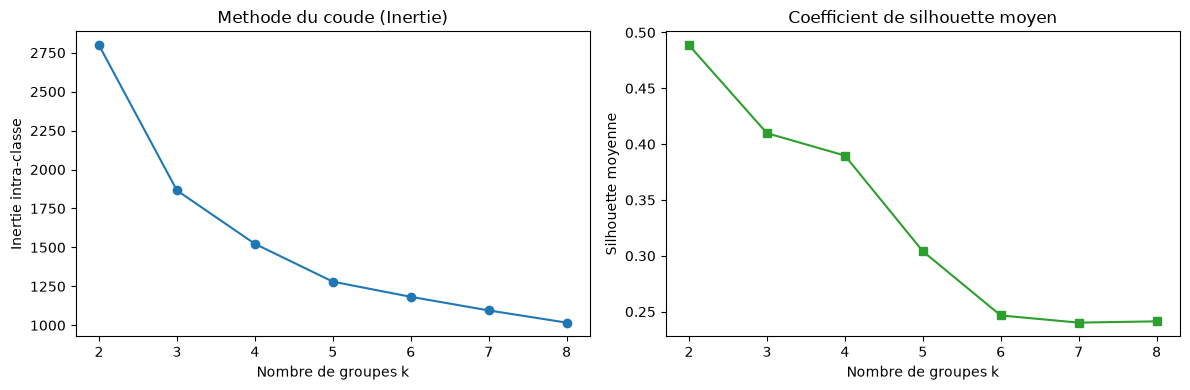

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Courbe du coude
axes[0].plot(df_k["k"], df_k["Inertie"], marker="o", color="#1f77b4")
axes[0].set_title("Methode du coude (Inertie)")
axes[0].set_xlabel("Nombre de groupes k")
axes[0].set_ylabel("Inertie intra-classe")
axes[0].set_xticks(k_valeurs)

# Score de silhouette
axes[1].plot(df_k["k"], df_k["Silhouette"], marker="s", color="#2ca02c")
axes[1].set_title("Coefficient de silhouette moyen")
axes[1].set_xlabel("Nombre de groupes k")
axes[1].set_ylabel("Silhouette moyenne")
axes[1].set_xticks(k_valeurs)

plt.tight_layout()
plt.show()


### Interprétation des courbes

- **Silhouette :** Le score est maximal pour k = 2 (0.49). Géométriquement, l'espace se coupe très nettement en deux blocs : d'un côté les machines peu chargées (M-01, M-02, M-05) et de l'autre les machines plus sollicitées ou usées (M-03, M-04, M-06). Pour k = 4, le score reste honorable (0.39), puis chute sous 0.30 pour k supérieur ou égal à 5.
- **Inertie (coude) :** La courbe décroît de façon continue sans cassure franche, mais la pente s'adoucit à partir de k = 3 et k = 4.


---
## 3. Segmentation en k = 4 régimes et profilage métier

### Pourquoi retenir k = 4 ?
Bien que k = 2 donne la plus forte silhouette, ce découpage est trop simpliste pour la maintenance : il regroupe dans un même bloc la charge nominale et les incidents critiques.  
Le choix de k = 4 est le compromis recommandé par le cours : il permet de séparer la marche légère, le régime nominal, la forte charge et les pannes critiques.


In [7]:
km4 = KMeans(n_clusters=4, n_init=20, init="k-means++", random_state=SEED)
clusters_bruts = km4.fit_predict(X_std)

df_analyse = pd.DataFrame(X_raw, columns=mesures)
df_analyse["defaut"] = df["defaut"].values
df_analyse["machine_id"] = df["machine_id"].values
df_analyse["cluster_brut"] = clusters_bruts

# Tri des 4 groupes par temperature mediane croissante (0 a 3)
medianes_temp = df_analyse.groupby("cluster_brut")["temperature"].median().sort_values()
mapping_regimes = {clust: idx for idx, clust in enumerate(medianes_temp.index)}
df_analyse["regime"] = df_analyse["cluster_brut"].map(mapping_regimes)

print("Mapping des clusters bruts vers regimes ordonnes (0 a 3) :", mapping_regimes)


Mapping des clusters bruts vers regimes ordonnes (0 a 3) : {1: 0, 2: 1, 3: 2, 0: 3}


### Profil physique moyen des 4 régimes

Pour chaque régime, je calcule les médianes dans leurs unités d'origine (°C, mm/s, A, pièces/min) ainsi que le taux de défaut constaté a posteriori.


In [8]:
tableau_profil = df_analyse.groupby("regime").agg(
    Effectif=("temperature", "count"),
    Part_pct=("temperature", lambda s: len(s) / len(df_analyse) * 100),
    Temperature_med_C=("temperature", "median"),
    Vibration_med_mms=("vibration", "median"),
    Courant_med_A=("courant", "median"),
    Cadence_med_cpm=("cadence", "median"),
    Taux_defauts_pct=("defaut", lambda s: s.mean() * 100)
).reset_index()

tableau_profil


,regime,Effectif,Part_pct,Temperature_med_C,Vibration_med_mms,Courant_med_A,Cadence_med_cpm,Taux_defauts_pct
0,0,713,41.26,72.13,1.76,12.02,55.44,3.51
1,1,584,33.80,78.69,2.98,15.15,47.95,5.48
2,2,362,20.95,84.40,4.12,17.36,42.27,15.75
3,3,69,3.99,90.57,6.15,20.54,34.51,72.46


### Croisement avec les identifiants machine


In [9]:
crosstab_machines = pd.crosstab(df_analyse["machine_id"], df_analyse["regime"], margins=True)
crosstab_machines.columns = [f"Regime {c}" if isinstance(c, int) else c for c in crosstab_machines.columns]
crosstab_machines


,Regime 0,Regime 1,Regime 2,Regime 3,All
machine_id,,,,,
M-01,264,24,0,0,288
M-02,261,16,11,0,288
M-03,1,262,13,12,288
M-04,0,202,66,20,288
M-05,187,77,24,0,288
M-06,0,3,248,37,288
All,713,584,362,69,1728


### Analyse du tableau croisé

Le tableau montre une répartition très nette par machine :
- **Régime 0 :** Rassemble quasi exclusivement M-01 (264 relevés), M-02 (261 relevés) et M-05 (187 relevés). Ce sont les machines les plus froides et stables de l'atelier (taux de défaut très bas : 3.5 %).
- **Régime 1 :** Dominé par M-03 (262), M-04 (202) et M-05 (77). C'est le régime de marche nominale stabilisée (taux de défaut de 5.5 %).
- **Régime 2 :** Concentre principalement M-06 (248) et une partie de M-04 (66). Les vibrations montent à 4.0 mm/s et le taux de défaut passe à 15.8 %.
- **Régime 3 :** Ne compte que 69 relevés au total, majoritairement issus de M-06 (37) et M-04 (20). La température monte à 90.6 °C et la vibration à 5.56 mm/s. C'est un régime critique où le taux de pièces défectueuses grimpe à 72.5 %.


---
## 4. Nommage prudent et actions de maintenance

À partir des médianes physiques et du taux de défauts, je donne un nom à chaque régime et je précise l'action à mener pour l'équipe de maintenance.


In [10]:
actions_maintenance = pd.DataFrame([
    {
        "Regime": 0,
        "Nom": "Ralenti / charge legere",
        "Profil physique": "Temperature basse (72.1 °C), vibration faible (1.63 mm/s), courant faible (12.0 A), cadence elevee, defauts quasi nuls (3.5 %).",
        "Action de maintenance": "Fonctionnement optimal. Surveillance standard de routine."
    },
    {
        "Regime": 1,
        "Nom": "Regime nominal stabilise",
        "Profil physique": "Temperature normale (78.7 °C), vibration moderee (2.76 mm/s), courant moyen (15.2 A), cadence soutenue (48 pcs/min), defauts faibles (5.5 %).",
        "Action de maintenance": "Controle de routine des niveaux de lubrifiant lors des changements d'equipe."
    },
    {
        "Regime": 2,
        "Nom": "Forte charge / usure moderee",
        "Profil physique": "Temperature elevee (84.4 °C), vibration proche du seuil (4.01 mm/s), courant fort (17.4 A), defauts a 15.8 %.",
        "Action de maintenance": "Surveillance rapprochee sur M-06 et M-04. Verification du refroidissement et lubrification des paliers."
    },
    {
        "Regime": 3,
        "Nom": "Regime severe / incident",
        "Profil physique": "Surchauffe (90.6 °C), vibrations critiques (5.56 mm/s > 4.2), surintensite (20.5 A), defauts massifs (72.5 %).",
        "Action de maintenance": "Arret programme prioritaire pour controle de la broche et remplacement du roulement use."
    }
])

pd.set_option("display.max_colwidth", None)
actions_maintenance


,Regime,Nom,Profil physique,Action de maintenance
0,0,Ralenti / charge legere,"Temperature basse (72.1 °C), vibration faible (1.63 mm/s), courant faible (12.0 A), cadence elevee, defauts quasi nuls (3.5 %).",Fonctionnement optimal. Surveillance standard de routine.
1,1,Regime nominal stabilise,"Temperature normale (78.7 °C), vibration moderee (2.76 mm/s), courant moyen (15.2 A), cadence soutenue (48 pcs/min), defauts faibles (5.5 %).",Controle de routine des niveaux de lubrifiant lors des changements d'equipe.
2,2,Forte charge / usure moderee,"Temperature elevee (84.4 °C), vibration proche du seuil (4.01 mm/s), courant fort (17.4 A), defauts a 15.8 %.",Surveillance rapprochee sur M-06 et M-04. Verification du refroidissement et lubrification des paliers.
3,3,Regime severe / incident,"Surchauffe (90.6 °C), vibrations critiques (5.56 mm/s > 4.2), surintensite (20.5 A), defauts massifs (72.5 %).",Arret programme prioritaire pour controle de la broche et remplacement du roulement use.


---
## 5. Effet de l'échelle (segmentation sur données brutes)

Pour vérifier l'importance de la standardisation, j'exécute le même K-means (k = 4, 20 initialisations) directement sur les données brutes non standardisées `X_raw`.


In [11]:
km_raw = KMeans(n_clusters=4, n_init=20, init="k-means++", random_state=SEED)
labels_raw = km_raw.fit_predict(X_raw)

ari_echelle = adjusted_rand_score(df_analyse["regime"], labels_raw)
print(f"Indice de Rand ajuste (ARI) entre partition brute et standardisee : {ari_echelle:.4f}")


Indice de Rand ajuste (ARI) entre partition brute et standardisee : 0.4403


In [12]:
# Comparaison des centres dans les unites d'origine
centres_bruts = pd.DataFrame(km_raw.cluster_centers_, columns=mesures).sort_values("temperature").reset_index(drop=True)
centres_std = pd.DataFrame(scaler.inverse_transform(km4.cluster_centers_), columns=mesures).sort_values("temperature").reset_index(drop=True)

print("Centroides obtenus sur donnees brutes :")
print(centres_bruts.round(2))
print()
print("Centroides obtenus sur donnees standardisees (ramenes aux unites d'origine) :")
print(centres_std.round(2))


Centroides obtenus sur donnees brutes :
   temperature  vibration  courant  cadence
0        70.89       1.68    11.68    57.88
1        74.75       2.25    13.12    51.73
2        80.18       3.32    15.79    46.14
3        86.32       4.57    18.06    39.30

Centroides obtenus sur donnees standardisees (ramenes aux unites d'origine) :
   temperature  vibration  courant  cadence
0        72.16       1.79    12.00    55.43
1        78.65       3.02    15.11    47.65
2        84.17       4.09    17.30    42.24
3        90.53       6.15    20.43    34.57


### Pourquoi l'ARI chute à 0.44 ?

L'indice de Rand ajusté tombe à environ 0.44, ce qui prouve que les deux segmentations ne racontent pas la même histoire :
1. **L'amplitude des variables :**
   - La température (qui varie de ~65 à 95 °C, écart de 30) et la cadence (de ~30 à 60 pièces/min, écart de 30) ont des variations absolues de plusieurs dizaines d'unités. Leurs écarts au carré valent plusieurs centaines.
   - La vibration varie seulement entre 1.0 et 7.5 mm/s (écarts typiques de 1 à 3 mm/s), donc ses écarts au carré dépassent rarement 5 à 10.
2. **L'écrasement de la vibration :**
   - Sur données brutes, la distance euclidienne est captée à plus de 85 % par la température et la cadence. Le modèle découpe les données par tranches de cadence et de température, et passe à côté du régime d'alerte vibratoire à 5.56 mm/s.
   - La standardisation est donc indispensable : en donnant à chaque variable une variance de 1, elle permet au signal de vibration de jouer pleinement son rôle d'alerte mécanique.


---
## Conclusion générale du TP 2

- L'implémentation de K-means avec NumPy avec 20 relances aléatoires donne exactement la même solution que scikit-learn (ARI = 1.000, inertie = 1522.98).
- Même si la silhouette suggère k = 2, le découpage à k = 4 régimes est le plus adapté pour l'exploitation industrielle : il permet de séparer le régime de charge normale d'un régime critique (72.5 % de pièces défectueuses).
- Ce régime critique touche principalement la machine M-06 et ponctuellement M-04, ce qui valide l'hypothèse formulée au TP 1 sur l'état dégradé de M-06.
- Enfin, l'essai sur données brutes confirme qu'en l'absence de centrage-réduction, les signaux vibratoires critiques sont écrasés par la température et la cadence.
